In [2]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

In [3]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print(df.head())
print("Dataset shape:", df.shape)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [4]:
df = df.drop(columns=["customerID"])

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df = df.dropna()

print("Missing values:", df.isnull().sum().sum())
print(df["Churn"].value_counts())

Missing values: 0
Churn
No     5163
Yes    1869
Name: count, dtype: int64


In [5]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-1 Year", "1-2 Years", "2-4 Years", "4-6 Years"]
)

df["AvgMonthlySpend"] = (
    df["TotalCharges"] / df["tenure"].replace(0, 1)
)

service_columns = [
    "PhoneService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV",
    "StreamingMovies"
]

df["NumberOfServices"] = df[service_columns].eq("Yes").sum(axis=1)

print(df.head())

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  ...  \
0  No phone service             DSL             No          Yes  ...   
1                No             DSL            Yes           No  ...   
2                No             DSL            Yes          Yes  ...   
3  No phone service             DSL            Yes           No  ...   
4                No     Fiber optic             No           No  ...   

  StreamingMovies        Contract PaperlessBilling              PaymentMethod  \
0              No  Month-to-month              Yes           Electronic check

In [6]:
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5625, 22)
Testing data: (1407, 22)


In [7]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

print("Preprocessing pipeline created")

Preprocessing pipeline created


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(
        learning_rate=0.1, max_depth=2, n_estimators=100,
        random_state=42
    )
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    scores = cross_val_score(
        pipe, X_train, y_train, cv=cv, scoring="accuracy"
    )

    print(name, "CV accuracy:", round(scores.mean() * 100, 2), "%")

Logistic Regression CV accuracy: 80.52 %
Random Forest CV accuracy: 79.38 %
Gradient Boosting CV accuracy: 80.73 %


In [9]:
pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

params = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3],
    "model__n_estimators": [100, 150]
}

grid_search = GridSearchCV(
    pipeline, params, cv=cv,
    scoring="accuracy", n_jobs=-1
)

grid_search.fit(X_train, y_train)

final_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", round(grid_search.best_score_ * 100, 2), "%")

Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}
Best CV accuracy: 80.73 %


In [11]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print(classification_report(y_test, y_pred))

Accuracy: 79.18 %
ROC-AUC: 0.8383
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.64      0.50      0.56       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



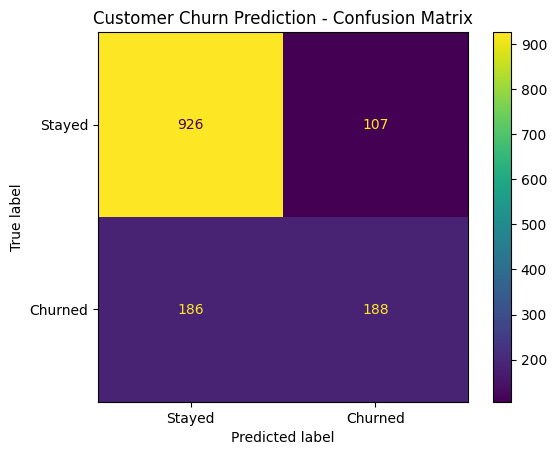

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    final_model, X_test, y_test,
    display_labels=["Stayed", "Churned"]
)

plt.title("Customer Churn Prediction - Confusion Matrix")
plt.show()

In [13]:
joblib.dump(final_model, "churn_pipeline.joblib")
print("Churn model saved successfully!")

Churn model saved successfully!


In [14]:
loaded_model = joblib.load("churn_pipeline.joblib")

sample_customer = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_customer)[0]
probability = loaded_model.predict_proba(sample_customer)[0][1]

print("Prediction:", "Churn" if prediction == 1 else "No Churn")
print("Churn Probability:", round(probability * 100, 2), "%")

Prediction: No Churn
Churn Probability: 3.15 %
